In [2]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline 

sys.path.insert(0, os.path.abspath('..'))
from config import Config

In [4]:
df = pd.read_csv(Config.LMD_2022_PATH, low_memory=False)
useful_cols = [col for col in df.columns if not col.startswith('Unnamed')]
print(f"Useful columns (excluding Unnamed): {len(useful_cols)}")

Useful columns (excluding Unnamed): 94


In [5]:
print(f"Total rows: {len(df)}")
print(f"Total columns: {len(df.columns)}")

Total rows: 293679
Total columns: 144


In [6]:
print(df['Label'].value_counts())
print("__________________ \n")
print(df['Label'].value_counts(normalize=True) * 100)

Label
1                          191194
0                          102354
0x5                           104
0x7                            12
0x3                             8
GetConfigurationOptions         1
172.217.18.10                   1
172.217.18.14                   1
142.250.186.170                 1
216.58.212.138                  1
142.250.184.206                 1
185.89.210.46                   1
Name: count, dtype: int64
__________________ 

Label
1                          65.103055
0                          34.852339
0x5                         0.035413
0x7                         0.004086
0x3                         0.002724
GetConfigurationOptions     0.000341
172.217.18.10               0.000341
172.217.18.14               0.000341
142.250.186.170             0.000341
216.58.212.138              0.000341
142.250.184.206             0.000341
185.89.210.46               0.000341
Name: proportion, dtype: float64


In [7]:
lmd2022_df = df[useful_cols].copy()
lmd2022_df.rename(columns={'Label': 'isMalicious'}, inplace=True)
lmd2022_df = lmd2022_df[(lmd2022_df['isMalicious'] == '1') | (lmd2022_df['isMalicious'] == '0')].copy()
lmd2022_df['isMalicious'].value_counts()

isMalicious
1    191194
0    102354
Name: count, dtype: int64

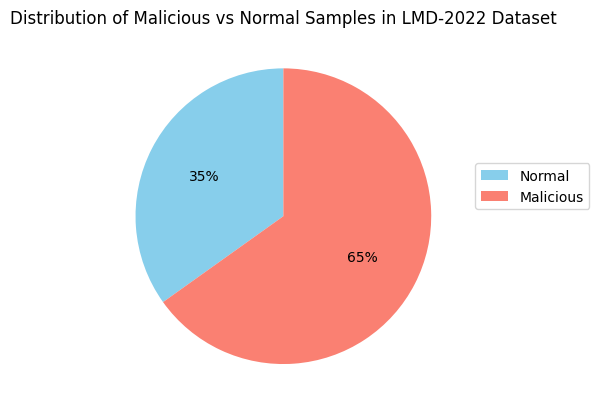

In [8]:
counts = lmd2022_df['isMalicious'].value_counts().sort_index()
fig, ax = plt.subplots()
counts.plot(kind='pie', colors=['skyblue', 'salmon'], autopct='%1.0f%%',startangle=90, ax=ax,labels=['', ''])
ax.set_title('Distribution of Malicious vs Normal Samples in LMD-2022 Dataset')
ax.legend(['Normal', 'Malicious'], loc='lower left', bbox_to_anchor=(1, 0.5))
ax.set_ylabel('')
plt.show()

In [9]:
sorted(lmd2022_df['EventID'].unique().tolist())

[1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 15, 16, 17, 18, 22, 23, 255]

In [10]:
# Sysmon Event ID Mapping
event_mapping = {
    1: 'Process Creation',
    2: 'File Creation Time Changed',
    3: 'Network Connection',
    4: 'Sysmon Service State Changed',
    5: 'Process Terminated',
    6: 'Driver Loaded',
    7: 'Image Loaded',
    8: 'CreateRemoteThread',
    10: 'ProcessAccess',
    11: 'FileCreate',
    12: 'RegistryEvent (Create/Delete)',
    13: 'RegistryEvent (Value Set)',
    15: 'FileCreateStreamHash',
    16: 'Sysmon Config Changed',
    17: 'PipeEvent (Created)',
    18: 'PipeEvent (Connected)',
    22: 'DNSEvent',
    23: 'FileDelete',
    255: 'Error'
}

events_info = lmd2022_df[['EventID', 'isMalicious']]
events_info['EventName'] = events_info['EventID'].map(event_mapping)

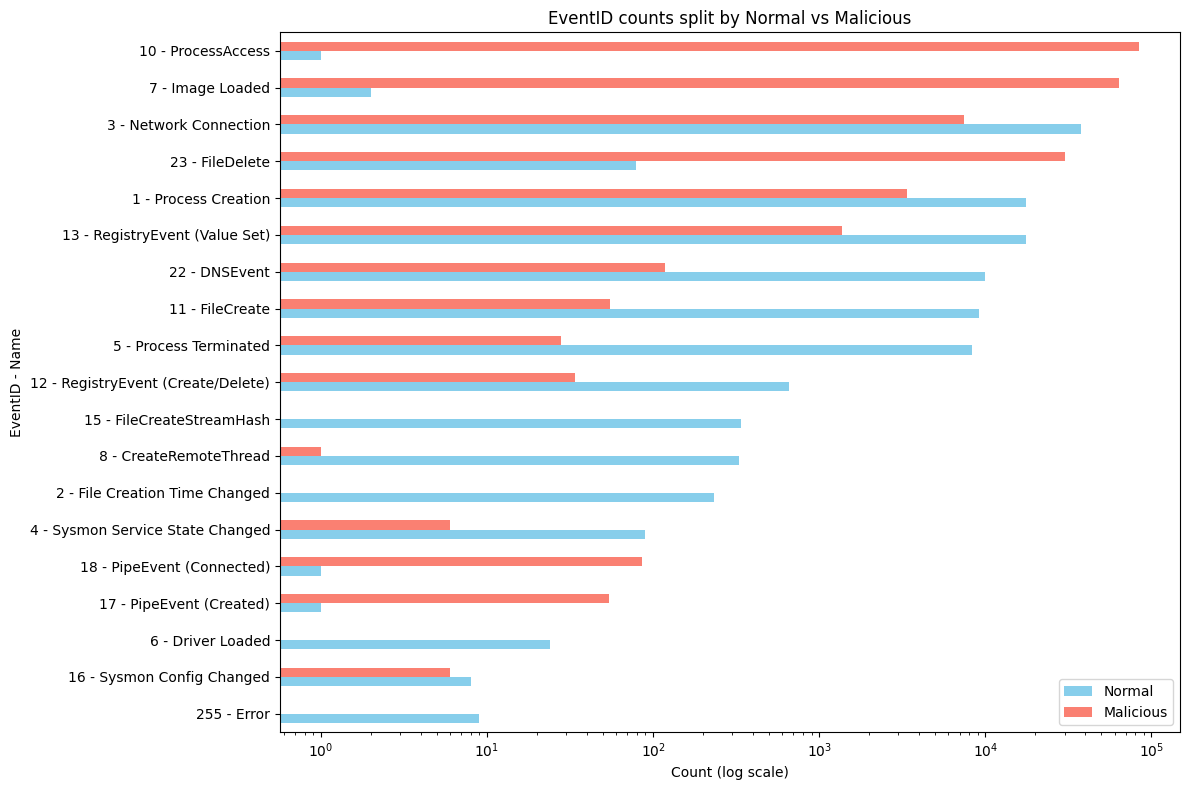

In [ ]:
counts = events_info.groupby(['EventID', 'isMalicious']).size().unstack(fill_value=0)
counts.columns = ['Normal', 'Malicious']
counts['Total'] = counts.sum(axis=1)
counts = counts.sort_values('Total').drop(columns='Total')

new_index = []

for eid in counts.index:
    if eid in event_mapping:
        event_name = event_mapping[eid]
    else:
        event_name = ''
    label = str(eid) + ' - ' + event_name
    new_index.append(label)

counts.index = new_index

# Plot
counts.plot.barh(figsize=(12, 8), color=['skyblue', 'salmon'])
plt.xscale('log')
plt.xlabel('Count (log scale)')
plt.ylabel('EventID - Name')
plt.title('EventID counts split by Normal vs Malicious')
plt.tight_layout()
plt.show()